# Radionica 2 — Prvi ML model: koliko vrijedi stan u Tuzli? 🏠

Na prvoj radionici smo **gledali** podatke. Danas ćemo pustiti računar da **uči** iz njih.

Plan:
1. Napravimo "model" bez ML-a — jedno pravilo koje smo sami smislili
2. Napravimo prvi pravi ML model (linearna regresija)
3. Dodajemo sve više informacija o stanovima
4. Isprobamo drugi model (random forest)
5. **Feature engineering** — sami smišljamo nove kolone
6. Leaderboard 🏆

Ćelije označene sa `# TODO` su vaše. Gdje vidite `___`, tu trebate nešto upisati.

## 0. Priprema
Pokrenite ćeliju ispod (Shift + Enter).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

def rmse(stvarno, predvidjeno):
    """Prosječna greška u KM (kvadratna — velike greške se kažnjavaju više)."""
    return np.sqrt(np.mean((np.array(stvarno) - np.array(predvidjeno)) ** 2))

def mae(stvarno, predvidjeno):
    """Prosječna greška u KM (obična — koliko u prosjeku promašimo)."""
    return np.mean(np.abs(np.array(stvarno) - np.array(predvidjeno)))

print("Sve spremno ✅")

Sve spremno ✅


In [4]:
import pandas as pd
import numpy as np
...

Ellipsis

## 1. Podaci
Ovo je proširena verzija stanova iz prošle radionice — sada imamo i godinu izgradnje, sprat, lift, parking, opis oglasa...

In [6]:
df = pd.read_csv("kalifornija_stanovi.csv")
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [7]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 2. "Model" bez ML-a: pravilo koje smo sami napisali

Najjednostavniji način da procijenimo cijenu stana:

> **cijena = kvadratura × 4160 KM**

Ovo je 🟢 *običan program* — mi smo napisali pravilo. Koliko je dobro?

In [11]:
print(df.columns)

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')


In [14]:
from sklearn.metrics import mean_absolute_error as mae, mean_squared_error
import numpy as np
def rmse(y_true, y_pred): return np.sqrt(mean_squared_error(y_true, y_pred))

# Pravilo izračuna / procjene za kalifornijske stanove
cijena_po_sobi = 30000

df["pravilo"] = df["total_rooms"] * cijena_po_sobi

print(f"MAE  (prosječna greška):        {mae(df['median_house_value'], df['pravilo']):,.0f} $")
print(f"RMSE (kažnjava velike greške):  {rmse(df['median_house_value'], df['pravilo']):,.0f} $")

MAE  (prosječna greška):        78,866,069 $
RMSE (kažnjava velike greške):  102,475,030 $


**MAE** = u prosjeku promašimo za toliko KM.
**RMSE** = slično, ali velike greške boli više. Danas koristimo RMSE za leaderboard — **manje je bolje**.

In [16]:
# TODO: Probajte neki drugi broj umjesto 4160. Možete li smanjiti grešku?
cijena_po_sobi = 35000

df["pravilo"] = df["total_rooms"] * cijena_po_sobi
print(f"RMSE: {rmse(df['median_house_value'], df['pravilo']):,.0f} $")

RMSE: 119,582,364 $


💬 Šta mislite — da li postoji *jedan* broj koji dobro radi za stan u Centru i stan u Gornjoj Tuzli?

## 3. Sakrijemo dio stanova (train / test)

Model uči na **80%** stanova (*train*), a provjeravamo ga na **20%** koje nikad nije vidio (*test*).

Kao ispit: ako ste vidjeli tačna pitanja unaprijed, odličan rezultat ne znači da znate gradivo. 📚

In [18]:
from sklearn.model_selection import train_test_split

y = df["median_house_value"]   # ono što predviđamo (target)

train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42)
print(f"Train: {len(train_idx)} stanova  |  Test: {len(test_idx)} stanova")

# Koliko je dobro naše pravilo na TEST stanovima?
rmse_pravilo = rmse(y[test_idx], df.loc[test_idx, "total_rooms"] * 35000)
print(f"Pravilo na test skupu: RMSE = {rmse_pravilo:,.0f} $")

Train: 16512 stanova  |  Test: 4128 stanova
Pravilo na test skupu: RMSE = 119,532,983 $


## 4. Prvi ML model 🔵 — linearna regresija

Ista ideja kao pravilo, ali **računar sam pronalazi brojeve**.

Svaki model u scikit-learn radi isto:
- `model.fit(X, y)` → uči
- `model.predict(X)` → predviđa

In [20]:
from sklearn.linear_model import LinearRegression

X = df[["total_rooms"]]

model = LinearRegression()
model.fit(X.loc[train_idx], y[train_idx])          # učenje
predikcije = model.predict(X.loc[test_idx])         # predviđanje

print(f"Model je sam naučio: cijena ≈ {model.coef_[0]:,.0f} $ × broj soba + {model.intercept_:,.0f} $")
print(f"RMSE na test skupu: {rmse(y[test_idx], predikcije):,.0f} $")

Model je sam naučio: cijena ≈ 7 $ × broj soba + 188,373 $
RMSE na test skupu: 113,440 $


Pogledajmo obje linije na grafikonu. Svaka tačka je jedan stan iz train skupa.
Isprekidane vertikalne crte su **greške** — model bira liniju kod koje su te greške ukupno najmanje.

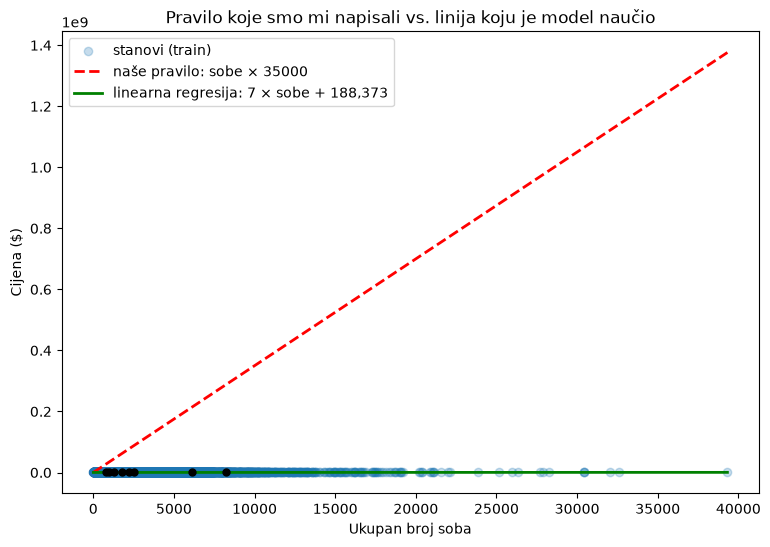

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Prilagođavamo x-osu da ide od najmanjeg do najvećeg broja soba
x = np.linspace(df["total_rooms"].min(), df["total_rooms"].max(), 100)

plt.figure(figsize=(9, 6))
plt.scatter(df.loc[train_idx, "total_rooms"], y[train_idx], alpha=0.25, label="stanovi (train)")
plt.plot(x, x * 35000, "r--", linewidth=2, label="naše pravilo: sobe × 35000")
plt.plot(x, model.predict(pd.DataFrame({"total_rooms": x})), "g-", linewidth=2,
         label=f"linearna regresija: {model.coef_[0]:,.0f} × sobe + {model.intercept_:,.0f}")

# prikaz nekoliko grešaka (udaljenost tačke od zelene linije)
primjer = df.loc[train_idx].sample(8, random_state=1)
for _, r in primjer.iterrows():
    p = model.predict(pd.DataFrame({"total_rooms": [r["total_rooms"]]}))[0]
    plt.plot([r["total_rooms"]] * 2, [r["median_house_value"], p], "k:", linewidth=1)
plt.scatter(primjer["total_rooms"], primjer["median_house_value"], color="black", s=25, zorder=3)

plt.xlabel("Ukupan broj soba")
plt.ylabel("Cijena ($)")
plt.title("Pravilo koje smo mi napisali vs. linija koju je model naučio")
plt.legend()
plt.show()


💬 Linije su slične — zato model nije mnogo bolji od pravila. Ima premalo informacija: stan od 60 m² u Centru i u Gornjoj Tuzli za njega je isti. Hajde da mu damo više.

## 5. Pomoćna funkcija `isprobaj`

Da ne pišemo isti kod svaki put: dajete joj **model** i **listu kolona**, ona uči i vrati grešku na test skupu.

In [22]:
rezultati = []   # ovdje pamtimo sve pokušaje

def isprobaj(model, kolone, opis=""):
    X = pd.get_dummies(df[kolone], dtype=float)     # tekstualne kolone pretvara u brojeve
    model.fit(X.loc[train_idx], y[train_idx])
    pred = model.predict(X.loc[test_idx])
    greska = rmse(y[test_idx], pred)
    ime = type(model).__name__
    rezultati.append({"model": ime, "broj_kolona": len(kolone), "RMSE": round(greska), "opis": opis})
    print(f"{ime:25s} {len(kolone):2d} kolona  →  RMSE = {greska:,.0f} $")
    return pred

isprobaj(LinearRegression(), ["total_rooms"], "samo broj soba");

LinearRegression           1 kolona  →  RMSE = 113,440 $


## 6. Više informacija → bolji model?

Dodajte brojčane kolone koje mislite da utiču na cijenu.
Dostupne: `kvadratura_m2`, `broj_soba`, `sprat`, `ukupno_spratova`, `godina_izgradnje`, `lift`, `parking`, `balkon`

In [25]:
# Popunjavanje praznih polja (NaN) nulama kako bi model mogao raditi
df = df.fillna(0)

# TODO: dopunite listu kolona
brojcane = ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income"]

pred = isprobaj(LinearRegression(), brojcane, "brojčane kolone")

LinearRegression           6 kolona  →  RMSE = 78,175 $


Pogledajmo kako model griješi — svaka tačka je jedan stan. Što bliže crvenoj liniji, to bolje.

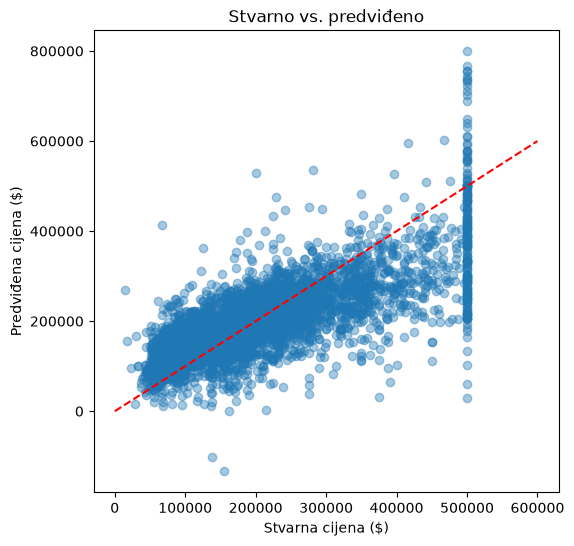

In [26]:
plt.figure(figsize=(6, 6))
plt.scatter(y[test_idx], pred, alpha=0.4)
plt.plot([0, 600000], [0, 600000], "r--") 
plt.xlabel("Stvarna cijena ($)")
plt.ylabel("Predviđena cijena ($)")
plt.title("Stvarno vs. predviđeno")
plt.show()

---
# ☕ Pauza
---

## 7. Tekstualne kolone: naselje, grijanje, stanje

Model razumije samo brojeve. `pd.get_dummies` pretvara npr. `naselje` u više kolona sa 0/1 — po jednu za svako naselje:

In [29]:
pd.get_dummies(df[["ocean_proximity"]], dtype=int).head()

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0,0,0,1,0
1,0,0,0,1,0
2,0,0,0,1,0
3,0,0,0,1,0
4,0,0,0,1,0


Funkcija `isprobaj` to već radi umjesto vas — samo dodajte kolone u listu.

In [30]:
# Dodajemo i tekstualnu kolonu za lokaciju zajedno sa brojčanim
sve_kolone = ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "ocean_proximity"]

pred = isprobaj(LinearRegression(), sve_kolone, "brojčane + lokacija")

LinearRegression           7 kolona  →  RMSE = 71,526 $


## 8. Drugi model: Random Forest 🌳🌳🌳

Puno malih stabala odlučivanja. Svako postavlja pitanja tipa *"veći od 70 m²?"*, *"u Centru?"*, *"izgrađen poslije 2010?"* — i na kraju **glasaju**.

Isti `fit` / `predict`, samo drugi model.

In [32]:
from sklearn.ensemble import RandomForestRegressor

# TODO: isprobajte RandomForestRegressor na istim kolonama kao gore
isprobaj(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), sve_kolone, "random forest")

RandomForestRegressor      7 kolona  →  RMSE = 63,000 $


array([ 90205.505, 230685.82 , 256260.075, ..., 494264.92 ,  98225.   ,
       155137.   ], shape=(4128,))

💬 Koji je bolji? Zašto mislite da je tako?

## 9. Feature engineering 🔧 — sami pravimo nove kolone

Sjetite se brainstorma: neke stvari nisu direktno u podacima, ali ih možemo **izvesti** iz postojećih kolona.

Primjer — starost zgrade:

In [34]:
# Pravimo novu kolonu koja označava da li je zgrada starija od 30 godina
df["stara_gradnja"] = (df["housing_median_age"] > 30).astype(int)

# Prikazujemo kako to izgleda
df[["housing_median_age", "stara_gradnja"]].head()

,housing_median_age,stara_gradnja
0,41.0,1
1,21.0,0
2,52.0,1
3,52.0,1
4,52.0,1


Ideje za nove kolone (napravite bar 2–3):

| Nova kolona | Iz čega? | Zašto bi mogla pomoći? |
|---|---|---|
| `prizemlje` | `sprat == 0` | prizemlje je često jeftinije |
| `zadnji_sprat` | `sprat == ukupno_spratova` | krov, vrućina ljeti... |
| `visoko_bez_lifta` | sprat ≥ 4 **i** nema lift | ko nosi kese na 6. sprat? 😅 |
| `nova_gradnja` / `stara_gradnja` | `starost` | cijena ne raste ravnomjerno sa godinama |
| `hitno` | `opis` sadrži "HITNO" | prodavac žuri → niža cijena |

Savjet: `(uslov).astype(int)` pretvara True/False u 1/0.

In [35]:
# Pravimo nove, pametne kolone za kalifornijske stanove
df["bogato_naselje"] = (df["median_income"] > 5.0).astype(int) # Prihodi iznad prosjeka
df["veliko_naselje"] = (df["population"] > 2000).astype(int)   # Više od 2000 stanovnika
df["mnogo_soba"]     = (df["total_rooms"] > 3000).astype(int)  # Kvartovi sa puno soba

# Umjesto godine izgradnje, koristimo housing_median_age
df["nova_gradnja"] = (df["housing_median_age"] < 10).astype(int) # Zgrade mlađe od 10 godina

# Prikazujemo kako to izgleda
df[["median_income", "bogato_naselje", "population", "veliko_naselje", "housing_median_age", "nova_gradnja"]].head()

,median_income,bogato_naselje,population,veliko_naselje,housing_median_age,nova_gradnja
0,8.3252,1,322.0,0,41.0,0
1,8.3014,1,2401.0,1,21.0,0
2,7.2574,1,496.0,0,52.0,0
3,5.6431,1,558.0,0,52.0,0
4,3.8462,0,565.0,0,52.0,0


In [37]:
# TODO: dodajte nove kolone u listu i isprobajte OBA modela
nove = ["bogato_naselje", "veliko_naselje", "mnogo_soba", "nova_gradnja"]

# Spajamo prethodne kolone (uključujući lokaciju) sa ovim novim
finalne_kolone = sve_kolone + nove

isprobaj(LinearRegression(), finalne_kolone, "+ moje nove kolone")
isprobaj(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), finalne_kolone, "+ moje nove kolone")

LinearRegression          11 kolona  →  RMSE = 71,482 $
RandomForestRegressor     11 kolona  →  RMSE = 62,982 $


array([ 88469.505, 228939.81 , 253301.59 , ..., 494122.905,  99293.   ,
       153450.5  ], shape=(4128,))

⚠️ **Pažnja — varanje!** Da li bi kolona `cijena_po_m2 = cijena_km / kvadratura_m2` pomogla? Bi — ali ona već sadrži odgovor. 
U stvarnosti ne znamo cijenu stana koji tek procjenjujemo. To se zove **data leakage**.

## 10. Leaderboard 🏆

Svi vaši pokušaji, od najboljeg:

In [36]:
pd.DataFrame(rezultati).sort_values("RMSE").reset_index(drop=True)

,model,broj_kolona,RMSE,opis
0,RandomForestRegressor,7,63000,random forest
1,LinearRegression,7,71526,brojčane + lokacija
2,LinearRegression,6,78175,brojčane kolone
3,LinearRegression,1,113440,samo broj soba


Upišite **najbolji RMSE** i **koje ste nove kolone napravile** u zajedničku tabelu.

Imate još vremena? Probajte:
- još neku novu kolonu (npr. iz `opis` — "pogled", "renoviran")
- izbaciti neku kolonu — da li model postaje gori ili bolji?
- `RandomForestRegressor(n_estimators=500, max_depth=10, ...)` — mijenjaju li postavke rezultat?

## 11. Zadaća 📝

Izaberite **jedno**:

1. **Pravi oglas:** nađite jedan stvarni oglas za stan u Tuzli (OLX), upišite njegove podatke i pogledajte koliko vaš model griješi. Da li je oglas "preskup" ili "povoljan"?
2. **Nova kolona:** smislite i napravite još jednu novu kolonu. Da li se RMSE smanjio? Napišite u 2–3 rečenice zašto mislite da jeste / nije.

Za opciju 1 možete koristiti ovaj kod:

In [38]:
# Primjer: procjena jedne nekretnine u Kaliforniji (prilagodite vrijednosti)
moja_nekretnina = {
    "housing_median_age": 25, 
    "total_rooms": 1500, 
    "total_bedrooms": 300, 
    "population": 800, 
    "households": 280, 
    "median_income": 4.5, 
    "ocean_proximity": "NEAR BAY"
}

# Model treba iste kolone kao pri učenju — zato procjenu radimo kroz isti postupak:
novi = pd.DataFrame([moja_nekretnina])

# Definiramo listu svih kolona koje smo koristili za treniranje
sve_koristene_kolone = ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "ocean_proximity", "bogato_naselje", "veliko_naselje", "mnogo_soba", "nova_gradnja"]

# Automatski dodajemo izračunate kolone i za naš novi stan
novi["bogato_naselje"] = (novi["median_income"] > 5.0).astype(int)
novi["veliko_naselje"] = (novi["population"] > 2000).astype(int)
novi["mnogo_soba"]     = (novi["total_rooms"] > 3000).astype(int)
novi["nova_gradnja"]   = (novi["housing_median_age"] < 10).astype(int)

# Priprema podataka za model
X_sve = pd.get_dummies(pd.concat([df[sve_koristene_kolone], novi[sve_koristene_kolone]]), dtype=float)

# Koristimo naš najjači model (RandomForest) ili linearnu regresiju za procjenu
rf_model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(X_sve.iloc[:-1].loc[train_idx], y[train_idx])
procjena = rf_model.predict(X_sve.iloc[[-1]])[0]

print(f"Procjena vrijednosti nekretnine: {procjena:,.0f} $")

Procjena vrijednosti nekretnine: 218,882 $


   m2  cijena
0  45  180000
1  60  240000
2  75  300000
3  90  370000


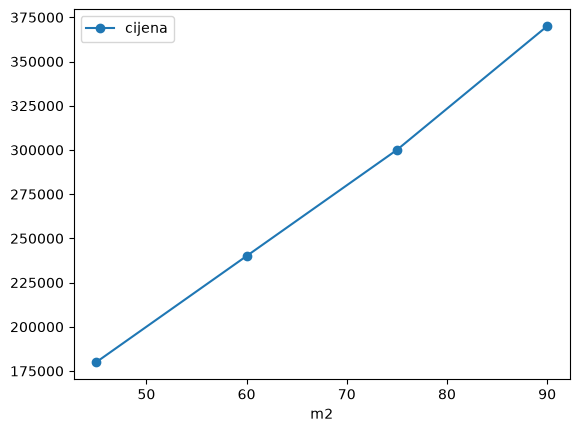

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({"m2": [45, 60, 75, 90], "cijena": [180000, 240000, 300000, 370000]})
print(df)
df.plot(x="m2", y="cijena", marker="o")
plt.show()